# 05 - Análise estatística, visualizações e Machine Learning (RA3)

Última etapa do projeto. Usa os dados preparados no RA1 (`data/processed/`) para responder, com estatística e
gráficos, às cinco perguntas analíticas de `docs/01_problema_e_perguntas.md`, e testa uma aplicação simples de
Machine Learning (classificação) para prever atrasos de entrega.

**Conteúdo**

0. Preparação da base por pedido
1. Análise estatística descritiva
2. Visualização e interpretação dos dados
3. Amostragem e representatividade
4. Aplicação de Machine Learning
5. Conclusões

Cada resultado é seguido de uma célula de texto com a interpretação.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4.5)

PROCESSED = Path("../data/processed")

colunas_data = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]
orders = pd.read_csv(PROCESSED / "olist_orders_dataset.csv", parse_dates=colunas_data)
customers = pd.read_csv(PROCESSED / "olist_customers_dataset.csv", dtype=str)
items = pd.read_csv(PROCESSED / "olist_order_items_dataset.csv")
payments = pd.read_csv(PROCESSED / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(PROCESSED / "olist_order_reviews_dataset.csv")
products = pd.read_csv(PROCESSED / "olist_products_dataset.csv")
sellers = pd.read_csv(PROCESSED / "olist_sellers_dataset.csv", dtype=str)

print("Pedidos carregados:", len(orders))

Pedidos carregados: 99441


## 0. Preparação da base por pedido

Os arquivos de `data/processed/` têm uma linha por pedido, item, pagamento ou avaliação. Para analisar, é preciso
juntá-los em **uma linha por pedido**. No RA1 isso não foi feito de propósito (o RA1 termina na preparação dos
dados); agora é a etapa certa.

**Decisões**

- **Só pedidos entregues** (`order_status == "delivered"` e com data de entrega): o atraso só existe quando a
  entrega aconteceu. Pedidos cancelados, indisponíveis ou ainda em andamento ficam fora desta análise.
- **Atraso:** `dias_atraso` é a data de entrega menos a data estimada, em dias. `atrasado` vale 1 quando
  `dias_atraso > 0`. `dias_entrega` é a data de entrega menos a data da compra.
- **Itens por pedido:** somamos preço, frete e peso, contamos os itens e usamos a categoria e o estado do
  vendedor do primeiro item.
- **Pagamento por pedido:** maior número de parcelas, valor total pago e tipo do primeiro pagamento.
- **Nota:** média das avaliações do pedido (quase todos têm uma só).
- **Pedido sem pagamento:** um pedido entregue não tem pagamento registrado e fica fora da base final.
- **`mesmo_estado`:** vale 1 quando cliente e vendedor estão no mesmo estado. É uma forma simples de aproximar a
  distância, sem usar a geolocalização.

In [2]:
entregues = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()].copy()

entregues["dias_entrega"] = (entregues["order_delivered_customer_date"] - entregues["order_purchase_timestamp"]).dt.days
entregues["dias_atraso"] = (entregues["order_delivered_customer_date"].dt.normalize()
                            - entregues["order_estimated_delivery_date"].dt.normalize()).dt.days
entregues["atrasado"] = (entregues["dias_atraso"] > 0).astype(int)
entregues["prazo_estimado"] = (entregues["order_estimated_delivery_date"] - entregues["order_purchase_timestamp"]).dt.days
entregues["mes_compra"] = entregues["order_purchase_timestamp"].dt.month

itens = items.merge(products[["product_id", "product_category_name_english", "product_weight_g"]], on="product_id", how="left")
itens = itens.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
por_pedido = itens.groupby("order_id").agg(
    n_itens=("order_item_id", "count"),
    preco=("price", "sum"),
    frete=("freight_value", "sum"),
    peso_g=("product_weight_g", "sum"),
    categoria=("product_category_name_english", "first"),
    estado_vendedor=("seller_state", "first"),
).reset_index()

pagamento = payments.groupby("order_id").agg(
    parcelas=("payment_installments", "max"),
    valor_pago=("payment_value", "sum"),
    tipo_pagamento=("payment_type", "first"),
).reset_index()

nota = reviews.groupby("order_id")["review_score"].mean().rename("nota").reset_index()

base = (entregues
        .merge(customers[["customer_id", "customer_state"]].rename(columns={"customer_state": "estado_cliente"}),
               on="customer_id", how="left")
        .merge(por_pedido, on="order_id", how="inner")
        .merge(pagamento, on="order_id", how="inner")
        .merge(nota, on="order_id", how="left"))

base["mesmo_estado"] = (base["estado_cliente"] == base["estado_vendedor"]).astype(int)
base["categoria"] = base["categoria"].fillna("sem_categoria")

print("Pedidos entregues:", len(entregues))
print("Pedidos na base final:", len(base), "| order_id único:", base["order_id"].is_unique)
print("Pedidos sem nota:", base["nota"].isna().sum())
base[["order_id", "estado_cliente", "estado_vendedor", "categoria", "preco", "frete", "dias_entrega",
      "dias_atraso", "atrasado", "nota"]].head()

Pedidos entregues: 96470
Pedidos na base final: 96469 | order_id único: True
Pedidos sem nota: 646


,order_id,estado_cliente,estado_vendedor,categoria,preco,frete,dias_entrega,dias_atraso,atrasado,nota
0,e481f51cbdc54678b7cc49136f2d6af7,SP,SP,housewares,29.99,8.72,8,-8,0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,SP,perfumery,118.70,22.76,13,-6,0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,SP,auto,159.90,19.22,9,-18,0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,MG,pet_shop,45.00,27.20,13,-13,0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,SP,stationery,19.90,8.72,2,-10,0,5.0


## 1. Análise estatística descritiva

**Medidas escolhidas, e por quê**

- **Tendência central:** média e **mediana**. Quando há poucos valores muito altos (prazo, preço, frete), a média
  é puxada para cima; a mediana mostra o valor típico.
- **Dispersão:** desvio-padrão e amplitude (máximo menos mínimo), para ver o quanto os valores variam.
- **Distribuição:** assimetria (`skew`; positivo significa cauda longa à direita), a frequência de cada nota e a
  proporção de pedidos atrasados.

In [3]:
colunas = ["dias_entrega", "dias_atraso", "preco", "frete", "valor_pago"]

resumo = base[colunas].agg(["count", "mean", "median", "std", "min", "max"]).T
resumo["amplitude"] = resumo["max"] - resumo["min"]
resumo["q1 (25%)"] = base[colunas].quantile(0.25)
resumo["q3 (75%)"] = base[colunas].quantile(0.75)
resumo["assimetria"] = base[colunas].skew()
resumo.round(2)

,count,mean,median,std,min,max,amplitude,q1 (25%),q3 (75%),assimetria
dias_entrega,96469.0,12.09,10.00,9.55,0.00,209.00,209.00,6.00,15.00,3.83
dias_atraso,96469.0,-11.88,-12.00,10.18,-147.00,188.00,335.00,-17.00,-7.00,2.02
preco,96469.0,137.04,86.50,209.05,0.85,13440.00,13439.15,45.90,149.90,9.89
frete,96469.0,22.79,17.17,21.56,0.00,1794.96,1794.96,13.85,24.02,12.28
valor_pago,96469.0,159.86,105.28,218.82,9.59,13664.08,13654.49,61.88,176.33,9.37


In [4]:
print("Proporção de pedidos no prazo (0) e atrasados (1), em %:")
print((base["atrasado"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nFrequência de cada nota (todas as avaliações), em %:")
print((reviews["review_score"].value_counts(normalize=True).sort_index() * 100).round(1))

Proporção de pedidos no prazo (0) e atrasados (1), em %:
atrasado
0    93.23
1     6.77
Name: proportion, dtype: float64

Frequência de cada nota (todas as avaliações), em %:
review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: proportion, dtype: float64


**Tempo de entrega.** A mediana é 10 dias e a média 12,1, com desvio-padrão de 9,6 e máximo de 209 dias (amplitude
de 209). A média maior que a mediana e a assimetria de 3,8 mostram uma cauda longa à direita: a maioria dos pedidos
chega em torno de 10 dias, mas poucos demoram muito mais.

**Atraso.** A mediana de `dias_atraso` é -12 (valor negativo significa entregue antes da data estimada): o pedido
típico chega 12 dias antes do prometido. Só **6,77%** dos pedidos entregues chegam depois da data estimada. O
desvio-padrão de 10,2 dias e a amplitude de 335 dias mostram que, nos poucos casos de atraso, ele pode ser grande.

**Preço, frete e valor pago.** Nas três variáveis a média fica bem acima da mediana (preço: média de R$ 137,04 contra
mediana de R$ 86,50; frete: R$ 22,79 contra R$ 17,17) e as assimetrias vão de 9 a 12, o que indica poucos pedidos
muito caros. Por isso, para falar do valor típico usamos a **mediana**: a média seria enganosa.

**Notas.** 57,8% das avaliações são nota 5 e 11,5% são nota 1; as notas 2, 3 e 4 somam 30,7%. A distribuição se
concentra nos extremos, com muito mais notas altas do que baixas.

## 2. Visualização e interpretação dos dados

Seis gráficos, cada um ligado a uma característica dos dados ou a uma das cinco perguntas analíticas.

### Gráfico 1 - Distribuição do tempo de entrega

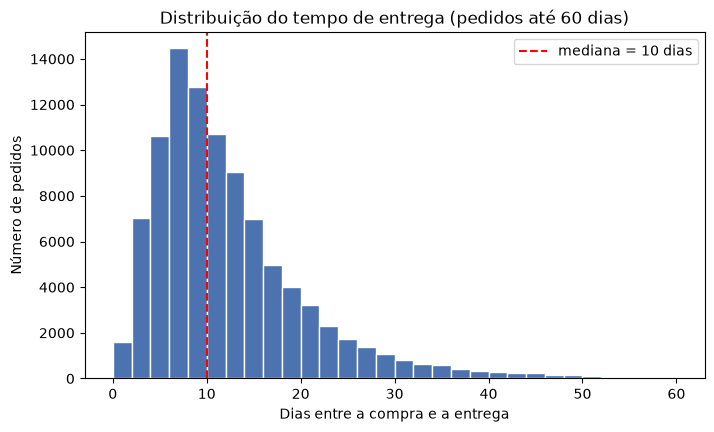

Pedidos com mais de 60 dias (fora do gráfico): 288


In [5]:
mediana_entrega = base["dias_entrega"].median()

plt.hist(base["dias_entrega"], bins=np.arange(0, 62, 2), color="#4C72B0", edgecolor="white")
plt.axvline(mediana_entrega, color="red", linestyle="--", label=f"mediana = {mediana_entrega:.0f} dias")
plt.title("Distribuição do tempo de entrega (pedidos até 60 dias)")
plt.xlabel("Dias entre a compra e a entrega")
plt.ylabel("Número de pedidos")
plt.legend()
plt.show()

print("Pedidos com mais de 60 dias (fora do gráfico):", (base["dias_entrega"] > 60).sum())

**Interpretação.** Metade dos pedidos chega entre 6 e 15 dias depois da compra, e a mediana de 10 dias fica dentro
dessa faixa. A cauda longa à direita (288 pedidos com mais de 60 dias ficaram fora do gráfico) confirma a
assimetria vista na tabela: o tempo de entrega costuma ser curto, mas alguns pedidos demoram muito.

### Gráfico 2 - Nota média conforme o atraso (pergunta 1)

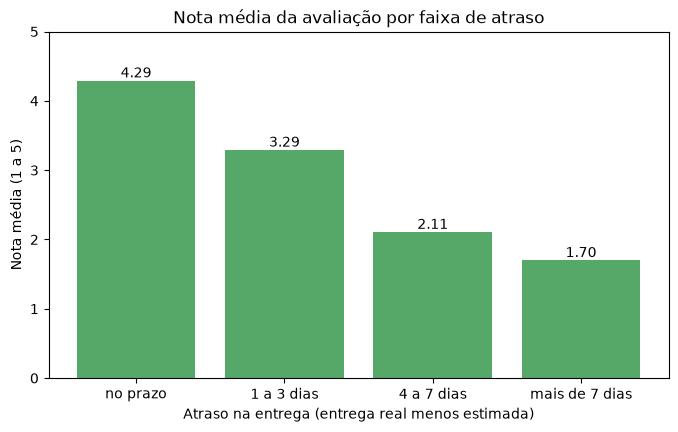

,pedidos,nota_media
dias_atraso,,
no prazo,89936,4.29
1 a 3 dias,1870,3.29
4 a 7 dias,1802,2.11
mais de 7 dias,2861,1.70


In [6]:
faixa_atraso = pd.cut(base["dias_atraso"], bins=[-1000, 0, 3, 7, 1000],
                      labels=["no prazo", "1 a 3 dias", "4 a 7 dias", "mais de 7 dias"])
nota_por_faixa = base.groupby(faixa_atraso, observed=True).agg(pedidos=("order_id", "count"), nota_media=("nota", "mean"))

barras = plt.bar(nota_por_faixa.index.astype(str), nota_por_faixa["nota_media"], color="#55A868")
plt.bar_label(barras, fmt="%.2f")
plt.title("Nota média da avaliação por faixa de atraso")
plt.xlabel("Atraso na entrega (entrega real menos estimada)")
plt.ylabel("Nota média (1 a 5)")
plt.ylim(0, 5)
plt.show()

nota_por_faixa.round(2)

**Interpretação (pergunta 1).** A nota cai com o atraso: 4,29 nos pedidos no prazo (89.936 pedidos), 3,29 com 1 a 3
dias de atraso, 2,11 com 4 a 7 dias e 1,70 com mais de 7 dias. Com apenas 1 a 3 dias de atraso a nota média já perde
1 ponto, e quanto maior o atraso, menor a nota. Ou seja, o atraso na entrega está fortemente associado a avaliações
piores. É uma associação, não prova de causa: o cliente também pode estar insatisfeito por outros motivos que
aparecem junto com o atraso.

### Gráfico 3 - Taxa de atraso por estado do cliente (pergunta 2)

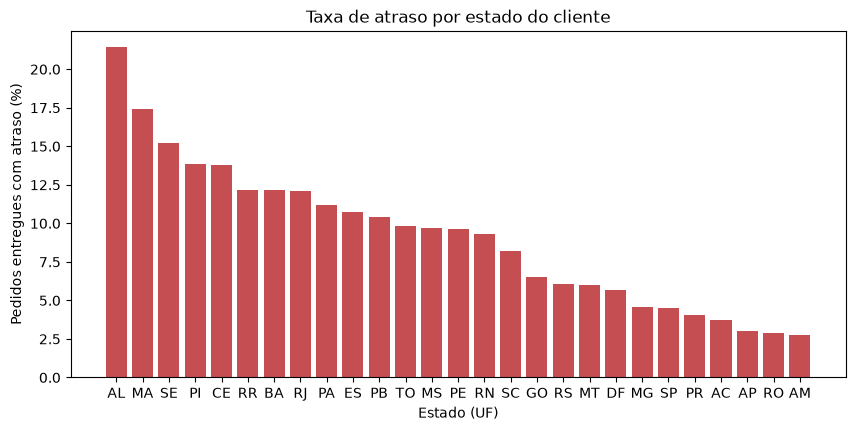

,pedidos,taxa_atraso
estado_cliente,,
AL,397,21.4
MA,717,17.4
SE,335,15.2
PI,476,13.9
CE,1279,13.8


In [7]:
por_uf = base.groupby("estado_cliente").agg(pedidos=("order_id", "count"), taxa_atraso=("atrasado", "mean"))
por_uf["taxa_atraso"] = por_uf["taxa_atraso"] * 100
por_uf = por_uf.sort_values("taxa_atraso", ascending=False)

plt.figure(figsize=(10, 4.5))
plt.bar(por_uf.index, por_uf["taxa_atraso"], color="#C44E52")
plt.title("Taxa de atraso por estado do cliente")
plt.xlabel("Estado (UF)")
plt.ylabel("Pedidos entregues com atraso (%)")
plt.show()

por_uf.round(1).head(5)

In [8]:
por_uf.round(1).tail(5)

,pedidos,taxa_atraso
estado_cliente,,
PR,4923,4.0
AC,80,3.8
AP,67,3.0
RO,243,2.9
AM,145,2.8


**Interpretação (pergunta 2).** A taxa de atraso varia muito entre estados. As maiores são AL (21,4%), MA (17,4%),
SE (15,2%), PI (13,9%) e CE (13,8%), todos do Nordeste; as menores são PR (4,0%), AC (3,8%), AP (3,0%), RO (2,9%) e
AM (2,8%). Os cinco estados com mais atrasos são todos nordestinos. Cuidado ao comparar estados com poucos pedidos:
AC, AP e RO têm 80, 67 e 243 pedidos, então suas taxas são menos estáveis do que a de PR (4.923 pedidos).

### Gráfico 4 - Taxa de atraso por categoria de produto (pergunta 3)

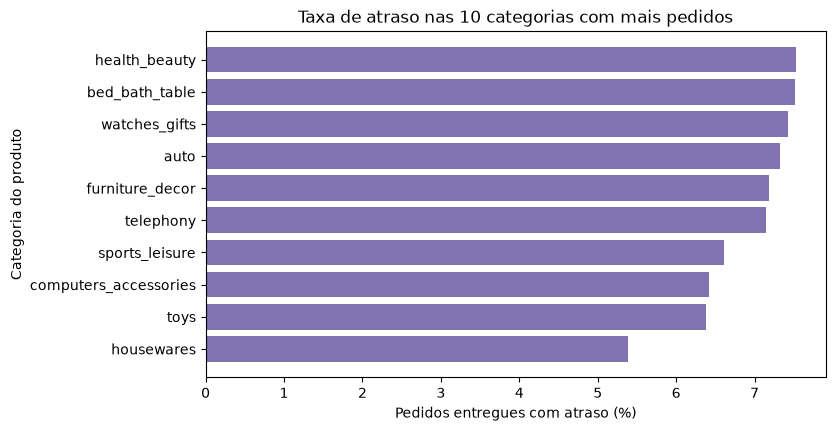

,pedidos,taxa_atraso,nota_media
categoria,,,
housewares,5695,5.39,4.20
toys,3779,6.38,4.24
computers_accessories,6501,6.41,4.08
sports_leisure,7492,6.61,4.23
telephony,4076,7.14,4.06
furniture_decor,6213,7.18,4.07
auto,3793,7.33,4.15
watches_gifts,5470,7.42,4.13
bed_bath_table,9171,7.51,4.01


In [9]:
top10 = base["categoria"].value_counts().head(10).index
por_categoria = (base[base["categoria"].isin(top10)]
                 .groupby("categoria").agg(pedidos=("order_id", "count"), taxa_atraso=("atrasado", "mean"),
                                           nota_media=("nota", "mean")))
por_categoria["taxa_atraso"] = por_categoria["taxa_atraso"] * 100
por_categoria = por_categoria.sort_values("taxa_atraso")

plt.barh(por_categoria.index, por_categoria["taxa_atraso"], color="#8172B2")
plt.title("Taxa de atraso nas 10 categorias com mais pedidos")
plt.xlabel("Pedidos entregues com atraso (%)")
plt.ylabel("Categoria do produto")
plt.show()

por_categoria.round(2)

**Interpretação (pergunta 3).** Entre as 10 categorias com mais pedidos, a taxa de atraso fica numa faixa estreita,
de 5,4% (housewares) a 7,5% (health_beauty), e as notas médias também são parecidas (de 4,01 a 4,24). Nas categorias
mais vendidas, a categoria do produto tem relação fraca com o atraso e com a nota. Há alguma diferença (por exemplo,
bed_bath_table tem a menor nota média, 4,01, e uma das maiores taxas de atraso, 7,5%), mas ela é pequena perto da
diferença entre estados (de 2,8% a 21,4%).

### Gráfico 5 - Frete conforme cliente e vendedor estejam no mesmo estado (pergunta 4)

O frete é comparado entre pedidos em que cliente e vendedor estão no mesmo estado (distância menor) e pedidos
entre estados diferentes. Os valores extremos não são desenhados (`showfliers=False`) para não esconder a caixa.

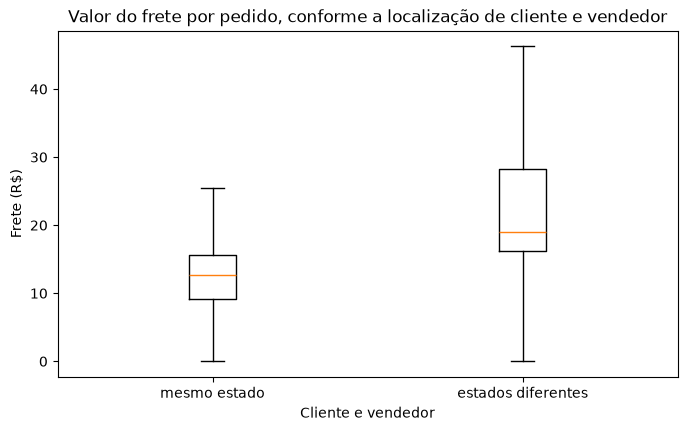

,pedidos,frete_mediano,nota_media,taxa_atraso
mesmo_estado,,,,
0,61768,19.04,4.096,0.080
1,34701,12.70,4.263,0.045


In [10]:
mesmo = base.loc[base["mesmo_estado"] == 1, "frete"]
outro = base.loc[base["mesmo_estado"] == 0, "frete"]

plt.boxplot([mesmo, outro], tick_labels=["mesmo estado", "estados diferentes"], showfliers=False)
plt.title("Valor do frete por pedido, conforme a localização de cliente e vendedor")
plt.xlabel("Cliente e vendedor")
plt.ylabel("Frete (R$)")
plt.show()

base.groupby("mesmo_estado").agg(pedidos=("order_id", "count"), frete_mediano=("frete", "median"),
                                 nota_media=("nota", "mean"), taxa_atraso=("atrasado", "mean")).round(3)

**Interpretação (pergunta 4).** O frete mediano é menor quando cliente e vendedor estão no mesmo estado: R$ 12,70
contra R$ 19,04 entre estados diferentes. Esses pedidos também recebem notas melhores (média de 4,26 contra 4,10) e
atrasam menos (4,5% contra 8,0%). Usando o mesmo estado como forma simples de aproximar a distância, pedidos mais
próximos têm frete menor, nota maior e menos atrasos. Limitação: "mesmo estado" é uma medida grosseira de distância
(um pedido dentro de um estado grande pode percorrer mais que um entre estados vizinhos); uma análise mais fina
precisaria calcular a distância pelas coordenadas.

### Gráfico 6 - Valor do pedido conforme o número de parcelas (pergunta 5)

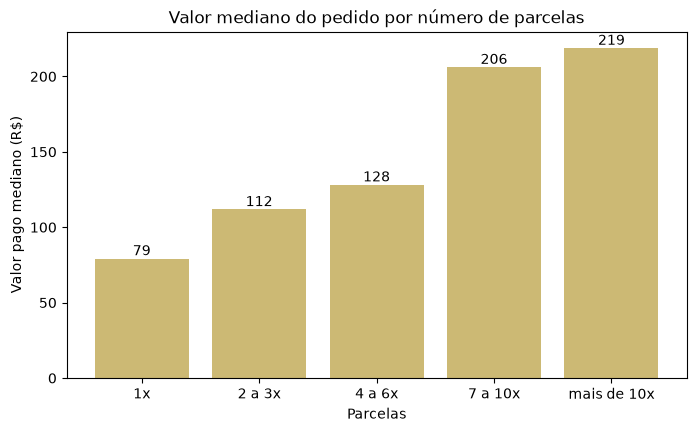

,pedidos,valor_mediano
parcelas,,
1x,46813,79.24
2 a 3x,22157,111.82
4 a 6x,15736,128.20
7 a 10x,11434,206.12
mais de 10x,329,218.80


In [11]:
faixa_parcelas = pd.cut(base["parcelas"], bins=[0, 1, 3, 6, 10, 100],
                        labels=["1x", "2 a 3x", "4 a 6x", "7 a 10x", "mais de 10x"])
valor_por_parcelas = base.groupby(faixa_parcelas, observed=True).agg(pedidos=("order_id", "count"),
                                                                     valor_mediano=("valor_pago", "median"))

barras = plt.bar(valor_por_parcelas.index.astype(str), valor_por_parcelas["valor_mediano"], color="#CCB974")
plt.bar_label(barras, fmt="%.0f")
plt.title("Valor mediano do pedido por número de parcelas")
plt.xlabel("Parcelas")
plt.ylabel("Valor pago mediano (R$)")
plt.show()

valor_por_parcelas.round(2)

In [12]:
tipos = base.groupby("tipo_pagamento").agg(pedidos=("order_id", "count"), valor_mediano=("valor_pago", "median"))
tipos["participacao_%"] = tipos["pedidos"] / tipos["pedidos"].sum() * 100
tipos.round(1).sort_values("pedidos", ascending=False)

,pedidos,valor_mediano,participacao_%
tipo_pagamento,,,
credit_card,73213,108.9,75.9
boleto,19191,93.8,19.9
voucher,2582,84.1,2.7
debit_card,1483,89.6,1.5


**Interpretação (pergunta 5).** O valor do pedido cresce junto com o número de parcelas: a mediana é de R$ 79,24
nos pedidos pagos à vista (1x), chega a R$ 206,12 em 7 a 10 parcelas e a R$ 218,80 acima de 10 parcelas (essa última
faixa tem só 329 pedidos). O cartão de crédito é a forma de pagamento mais usada (75,9% dos pedidos), seguido do
boleto (19,9%); voucher e débito somam 4,2%. Pedidos mais caros tendem a ser parcelados em mais vezes.

## 3. Amostragem e representatividade

**Não foi usada amostragem:** a análise estatística usa todos os pedidos entregues da base. Na parte de Machine
Learning, os pedidos são divididos em treino e teste (seção 4). A tabela abaixo ajuda a avaliar se esses
registros representam o problema.

In [13]:
print(f"Pedidos na base original: {len(orders)} | pedidos usados na análise: {len(base)} ({len(base) / len(orders):.1%})")

print("\nPedidos por ano da compra:")
print(base["order_purchase_timestamp"].dt.year.value_counts().sort_index())

print("\nParticipação dos 5 maiores estados de cliente, em %:")
print((base["estado_cliente"].value_counts(normalize=True).head(5) * 100).round(1))

notas_extremas = reviews["review_score"].isin([1, 5]).mean() * 100
print(f"\nAvaliações com nota 1 ou 5: {notas_extremas:.1f}%")
print("Pedidos sem avaliação na base:", base["nota"].isna().sum())
print("Pedidos sem categoria de produto:", (base["categoria"] == "sem_categoria").sum())

Pedidos na base original: 99441 | pedidos usados na análise: 96469 (97.0%)

Pedidos por ano da compra:
order_purchase_timestamp
2016      266
2017    43426
2018    52777
Name: count, dtype: int64

Participação dos 5 maiores estados de cliente, em %:
estado_cliente
SP    42.0
RJ    12.8
MG    11.8
RS     5.5
PR     5.1
Name: proportion, dtype: float64

Avaliações com nota 1 ou 5: 69.3%
Pedidos sem avaliação na base: 646
Pedidos sem categoria de produto: 1351


**Origem e abrangência.** São dados reais e anonimizados de pedidos da Olist, um marketplace brasileiro, de 2016 a
2018, publicados pela própria empresa. A análise usa 96.469 pedidos (97,0% dos 99.441 da base): os entregues que
têm itens e pagamento registrados.

**Os registros representam o problema?** Em parte. Para entender atraso de entrega e satisfação **dentro da Olist**,
sim: são pedidos reais, com datas e notas. Mas há limites:

- **Um só marketplace e um período curto.** Os resultados não valem automaticamente para o comércio eletrônico
  brasileiro em geral nem para anos mais recentes. Quase todos os pedidos são de 2017 (43.426) e 2018 (52.777); 2016
  tem só 266.
- **Concentração geográfica.** SP responde por 42,0% dos pedidos, seguido de RJ (12,8%) e MG (11,8%). Estados
  pequenos têm poucos pedidos e taxas mais instáveis (por exemplo AP, com 67, e AC, com 80).
- **Viés da nota.** Só aparece a nota de quem decidiu avaliar, e 69,3% das avaliações são 1 ou 5: clientes muito
  satisfeitos ou muito insatisfeitos avaliam mais. Além disso, 646 pedidos entregues não têm avaliação.
- **Só pedidos entregues.** Cancelados e indisponíveis ficam de fora, então a análise não diz nada sobre pedidos
  que nunca chegaram.
- **Dados faltantes.** 1.351 pedidos (1,4%) não têm categoria de produto.

## 4. Aplicação de Machine Learning

**Problema preditivo (classificação):** prever se um pedido será entregue **com atraso**, usando só informações
que já existem no momento da compra. É útil porque atrasos são o centro do problema do projeto: um modelo assim
poderia indicar pedidos de risco antes da entrega.

**Variável-alvo (target):** `atrasado` (1 = entregue depois da data estimada, 0 = no prazo).

**Características (features):** estado do cliente, estado do vendedor, `mesmo_estado`, categoria do produto
(as 10 mais frequentes; as demais viram "outras"), preço, frete, peso, número de itens, prazo estimado em dias
(data estimada menos data da compra), número de parcelas, tipo de pagamento e mês da compra.

**Ficam de fora:** `dias_entrega`, `dias_atraso` e a nota. Eles só existem **depois** da entrega, e usá-los faria
o modelo "colar" a resposta (vazamento de dados).

**Divisão dos dados:** 80% para treino e 20% para teste, com `stratify` para manter a mesma proporção de pedidos
atrasados nos dois grupos e `random_state` fixo para o resultado ser reproduzível.

**Modelos:** um modelo de referência que sempre responde "no prazo" (`DummyClassifier`) e uma **floresta
aleatória** (`RandomForestClassifier`), que reúne muitas árvores de decisão e decide por votação. Como só uma
pequena parte dos pedidos atrasa, usamos `class_weight="balanced"` para o modelo dar mais peso aos atrasados.

In [14]:
top_categorias = base["categoria"].value_counts().head(10).index
dados = base.copy()
dados["categoria"] = dados["categoria"].where(dados["categoria"].isin(top_categorias), "outras")

variaveis_numericas = ["preco", "frete", "peso_g", "n_itens", "prazo_estimado", "parcelas", "mes_compra", "mesmo_estado"]
variaveis_texto = ["estado_cliente", "estado_vendedor", "categoria", "tipo_pagamento"]

X = pd.get_dummies(dados[variaveis_numericas + variaveis_texto], columns=variaveis_texto)
y = dados["atrasado"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Características (colunas) depois de transformar o texto em colunas 0/1:", X.shape[1])
print("Treino:", len(X_treino), "pedidos | Teste:", len(X_teste), "pedidos")
print("Atrasados no treino: %.2f%% | no teste: %.2f%%" % (y_treino.mean() * 100, y_teste.mean() * 100))

Características (colunas) depois de transformar o texto em colunas 0/1: 72
Treino: 77175 pedidos | Teste: 19294 pedidos
Atrasados no treino: 6.77% | no teste: 6.77%


In [15]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

modelo = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=20,
                                class_weight="balanced", random_state=42, n_jobs=-1)
modelo.fit(X_treino, y_treino)
print("Modelo treinado.")

Modelo treinado.


In [16]:
def avaliar(nome, m):
    previsto = m.predict(X_teste)
    probabilidade = m.predict_proba(X_teste)[:, 1]
    return {
        "modelo": nome,
        "acurácia": accuracy_score(y_teste, previsto),
        "precisão": precision_score(y_teste, previsto, zero_division=0),
        "recall": recall_score(y_teste, previsto),
        "F1": f1_score(y_teste, previsto),
        "AUC": roc_auc_score(y_teste, probabilidade),
    }


metricas = pd.DataFrame([avaliar("sempre 'no prazo' (referência)", baseline), avaliar("floresta aleatória", modelo)])
metricas.set_index("modelo").round(3)

,acurácia,precisão,recall,F1,AUC
modelo,,,,,
sempre 'no prazo' (referência),0.932,0.000,0.000,0.000,0.500
floresta aleatória,0.741,0.155,0.634,0.249,0.757


In [17]:
previsto = modelo.predict(X_teste)
pd.DataFrame(confusion_matrix(y_teste, previsto),
             index=["real: no prazo", "real: atrasado"],
             columns=["previsto: no prazo", "previsto: atrasado"])

,previsto: no prazo,previsto: atrasado
real: no prazo,13476,4511
real: atrasado,479,828


**Exemplos de previsões individuais.** A tabela abaixo mostra 10 pedidos do conjunto de teste (que o modelo não viu
no treino): 5 que realmente atrasaram e 5 que chegaram no prazo, sorteados com semente fixa. Ela traz o que o modelo
previu e a probabilidade de atraso que ele calculou. A proporção 5 e 5 serve só para mostrar os dois casos; na base
real, só 6,77% dos pedidos atrasam.

In [18]:
probabilidade = pd.Series(modelo.predict_proba(X_teste)[:, 1], index=X_teste.index)
previsao = pd.Series(modelo.predict(X_teste), index=X_teste.index)

sorteio = pd.concat([y_teste[y_teste == 1].sample(5, random_state=1),
                     y_teste[y_teste == 0].sample(5, random_state=1)]).index
nomes = {0: "no prazo", 1: "atrasado"}

exemplos = dados.loc[sorteio, ["estado_cliente", "categoria", "frete", "prazo_estimado"]].copy()
exemplos["real"] = y_teste.loc[sorteio].map(nomes)
exemplos["previsto"] = previsao.loc[sorteio].map(nomes)
exemplos["prob_atraso_%"] = (probabilidade.loc[sorteio] * 100).round(0).astype(int)
exemplos["acertou"] = (y_teste.loc[sorteio] == previsao.loc[sorteio]).map({True: "sim", False: "não"})
exemplos.reset_index(drop=True)

,estado_cliente,categoria,frete,prazo_estimado,real,previsto,prob_atraso_%,acertou
0,SC,sports_leisure,15.10,25,atrasado,atrasado,68,sim
1,PR,computers_accessories,15.10,20,atrasado,atrasado,62,sim
2,PI,auto,21.15,23,atrasado,atrasado,62,sim
3,RN,furniture_decor,41.95,29,atrasado,atrasado,62,sim
4,PR,outras,15.15,23,atrasado,no prazo,39,não
5,SP,furniture_decor,12.28,13,no prazo,no prazo,34,sim
6,SP,computers_accessories,12.90,26,no prazo,no prazo,33,sim
7,SC,outras,23.13,22,no prazo,atrasado,50,não
8,DF,watches_gifts,20.15,32,no prazo,no prazo,39,sim
9,SP,computers_accessories,15.30,21,no prazo,no prazo,33,sim


**Interpretação das previsões individuais.** Nesta amostra o modelo acertou 8 dos 10 pedidos. Dos 5 que realmente
atrasaram, encontrou 4 (com probabilidades de 62% a 68%) e deixou passar 1 (probabilidade de 39%). Dos 5 que chegaram
no prazo, acertou 4 e deu 1 alarme falso (probabilidade de 50%). Mesmo nos acertos, as probabilidades ficam em torno
de 60%: o modelo indica risco, não certeza. Atenção ao ler a tabela: ela tem 5 pedidos de cada tipo só para mostrar os
dois casos, e na base real apenas 6,77% dos pedidos atrasam. Por isso a amostra parece melhor do que o modelo é de
fato; o desempenho verdadeiro está nas métricas do conjunto de teste inteiro (recall de 0,634 e precisão de 0,155).

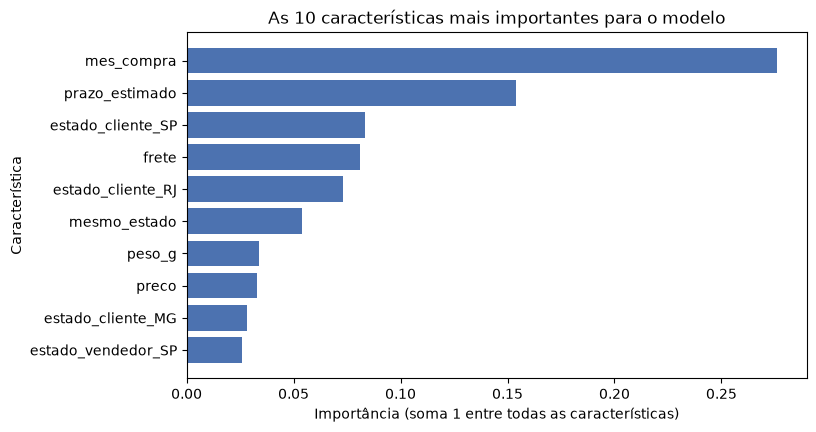

mes_compra            0.276
prazo_estimado        0.154
estado_cliente_SP     0.083
frete                 0.081
estado_cliente_RJ     0.073
mesmo_estado          0.054
peso_g                0.034
preco                 0.033
estado_cliente_MG     0.028
estado_vendedor_SP    0.026
dtype: float64

In [19]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values().tail(10)

plt.barh(importancias.index, importancias.values, color="#4C72B0")
plt.title("As 10 características mais importantes para o modelo")
plt.xlabel("Importância (soma 1 entre todas as características)")
plt.ylabel("Característica")
plt.show()

importancias.sort_values(ascending=False).round(3)

In [20]:
por_mes = base.groupby(base["order_purchase_timestamp"].dt.to_period("M")).agg(
    pedidos=("order_id", "count"), taxa_atraso=("atrasado", "mean"))
por_mes["taxa_atraso"] = (por_mes["taxa_atraso"] * 100).round(1)
por_mes[por_mes["pedidos"] > 500].sort_values("taxa_atraso", ascending=False).head(5)

,pedidos,taxa_atraso
order_purchase_timestamp,,
2018-03,7003,19.0
2018-02,6555,14.1
2017-11,7288,12.4
2017-12,5513,7.5
2018-05,6749,6.6


**Resultado.** O modelo de referência, que sempre responde "no prazo", acerta 93,2% dos pedidos (porque só 6,77%
atrasam), mas não identifica nenhum atrasado (recall 0). Por isso a **acurácia sozinha engana** neste problema. A
floresta aleatória tem acurácia menor (74,1%), mas **encontra 63,4% dos pedidos atrasados** (828 de 1.307 no teste),
com AUC de 0,757 (0,5 seria o acaso).

**Precisão baixa.** Dos 5.339 pedidos que o modelo marcou como atrasados, só 828 realmente atrasaram (precisão de
15,5%): ele gera muitos alarmes falsos (4.511). O F1 de 0,249 resume esse equilíbrio. Na prática, o modelo serve
para **chamar atenção para pedidos de risco**, não para decidir sozinho.

**O que mais pesa.** As características mais importantes são o mês da compra (0,276), o prazo estimado (0,154), o
estado do cliente SP (0,083), o frete (0,081) e o estado RJ (0,073). A tabela por mês mostra o porquê do primeiro
lugar: os atrasos se concentram em março de 2018 (19,0%), fevereiro de 2018 (14,1%) e novembro de 2017 (12,4%),
contra 6,77% no total. O modelo aprendeu que comprar nesses meses traz mais risco. Possíveis causas, como picos de
demanda, são hipóteses que estes dados sozinhos não confirmam; importância de característica também não prova causa.

**Limitações.** O modelo só usa informações da compra: não conhece distância real, transportadora, greves, feriados
nem lotação logística. Foi treinado com dados de 2016 a 2018 e os parâmetros foram fixados sem busca, por simplicidade.

## 5. Conclusões

**Principais resultados da análise estatística e dos gráficos**

- Só 6,77% dos pedidos entregues chegam depois da data estimada, e o pedido típico chega 12 dias antes do prometido.
- O atraso pesa na satisfação: a nota média é 4,29 no prazo e cai para 3,29 com 1 a 3 dias de atraso e 1,70 com mais
  de 7 dias (pergunta 1).
- O atraso depende muito da região: vai de 2,8% (AM) a 21,4% (AL), e os cinco estados com mais atrasos são todos do
  Nordeste (pergunta 2).
- Entre as categorias mais vendidas, a categoria quase não diferencia atraso (5,4% a 7,5%) nem nota (pergunta 3).
- Pedidos entre estados diferentes têm frete mediano maior (R$ 19,04 contra R$ 12,70), mais atrasos (8,0% contra 4,5%)
  e nota menor (4,10 contra 4,26) (pergunta 4).
- Pedidos de maior valor são pagos em mais parcelas, e o cartão de crédito aparece em 75,9% dos pedidos (pergunta 5).
- Os atrasos também se concentram em alguns meses: março de 2018 (19,0%), fevereiro de 2018 (14,1%) e novembro de
  2017 (12,4%).

**Desempenho do modelo de Machine Learning**

A floresta aleatória identifica 63,4% dos pedidos que vão atrasar (recall) e tem AUC de 0,757, claramente melhor que o
modelo de referência (recall 0 e AUC 0,5). Porém a precisão é de só 15,5%: a cada 100 pedidos marcados como
atrasados, cerca de 85 chegam no prazo. É um desempenho **modesto**, útil para priorizar atenção, não para decidir
sozinho. A acurácia (74,1%) não é uma boa medida aqui, porque 93,2% dos pedidos já são pontuais.

**Limitações dos dados e das análises**

- Os dados são de um só marketplace, de 2016 a 2018 (2016 com poucos pedidos), concentrados em SP, RJ e MG.
- A nota vem só de quem avaliou, com forte concentração em 1 e 5, e a análise exclui pedidos cancelados e indisponíveis.
- A distância foi aproximada por "mesmo estado", sem usar coordenadas; o modelo não conhece transportadora, greves,
  feriados nem lotação logística.
- As relações encontradas são **associações**: os dados não provam que uma coisa causa a outra.

**Relação com o problema do projeto**

O problema era entender quais fatores operacionais se associam à satisfação do cliente e aos atrasos de entrega. Os
resultados mostram que o atraso é o fator mais claramente ligado à nota (de 4,29 para 1,70), que região e distância
aproximada se ligam ao atraso (Nordeste e pedidos entre estados com mais atrasos), que o período da compra pesa
muito (picos em fevereiro e março de 2018 e em novembro de 2017) e que a categoria do produto pesa pouco. O modelo
mostra que já é possível apontar parte dos pedidos de risco no momento da compra, ainda com muitos alarmes falsos.
Assim, as cinco perguntas analíticas do projeto foram respondidas dentro dos limites dos dados.